In [5]:
import pandas as pd
df = pd.read_csv("Uncleaned_Financial_Transactions_Dataset.csv")
df.head()

,TransactionID,CustomerID,AccountType,TransactionDate,TransactionAmount,TransactionType,PaymentMethod,Branch,Status,DeviceID,Merchant,RiskScore,Remarks
0,TXN000001,C1154,Current,2025-02-19,80992.00,Credit,Card,Chennai,Pending,D696,Amazon,65,OK
1,TXN000002,C1088,Current,2026-03-05,53713.81,Credit,NEFT,Chennai,Failed,D534,Amazon,73,OK
2,TXN000003,C1228,Business,2025-03-05,30994.30,Debit,UPI,Bengaluru,Completed,D670,Flipkart,38,OK
3,TXN000004,C1553,Savings,2025-11-12,104813.80,Credit,UPI,Hyderabad,Failed,D754,Flipkart,48,OK
4,TXN000005,C1729,Savings,2025-03-03,24402.77,Credit,IMPS,Kochi,Failed,D537,ATM,60,OK


In [6]:
df.shape

(4050, 13)

In [7]:
df.info

<bound method DataFrame.info of      TransactionID CustomerID AccountType TransactionDate  TransactionAmount  \
0        TXN000001      C1154     Current      2025-02-19           80992.00   
1        TXN000002      C1088     Current      2026-03-05           53713.81   
2        TXN000003      C1228    Business      2025-03-05           30994.30   
3        TXN000004      C1553     Savings      2025-11-12          104813.80   
4        TXN000005      C1729     Savings      2025-03-03           24402.77   
...            ...        ...         ...             ...                ...   
4045     TXN003859      C1275    Business      2025-03-29          105586.67   
4046     TXN001859      C1087    Business      2026-05-10           68363.92   
4047     TXN002311      C1332     Current      2026-02-28           78080.10   
4048     TXN003628      C1014     Current      2025-10-01          240706.21   
4049     TXN003778      C1614     Savings      2025-01-09           42890.73   

     Tr

In [8]:
df.head()

,TransactionID,CustomerID,AccountType,TransactionDate,TransactionAmount,TransactionType,PaymentMethod,Branch,Status,DeviceID,Merchant,RiskScore,Remarks
0,TXN000001,C1154,Current,2025-02-19,80992.00,Credit,Card,Chennai,Pending,D696,Amazon,65,OK
1,TXN000002,C1088,Current,2026-03-05,53713.81,Credit,NEFT,Chennai,Failed,D534,Amazon,73,OK
2,TXN000003,C1228,Business,2025-03-05,30994.30,Debit,UPI,Bengaluru,Completed,D670,Flipkart,38,OK
3,TXN000004,C1553,Savings,2025-11-12,104813.80,Credit,UPI,Hyderabad,Failed,D754,Flipkart,48,OK
4,TXN000005,C1729,Savings,2025-03-03,24402.77,Credit,IMPS,Kochi,Failed,D537,ATM,60,OK


In [ ]:
#step 1: removing duplicate

In [9]:
df.duplicated().sum()

np.int64(45)

In [10]:
df = df.drop_duplicates()

In [11]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#step2: Handling missing value

In [12]:
df.isnull().sum()

TransactionID          0
CustomerID             0
AccountType          100
TransactionDate        0
TransactionAmount      0
TransactionType        0
PaymentMethod          0
Branch                 0
Status                70
DeviceID               0
Merchant             121
RiskScore              0
Remarks                0
dtype: int64

In [13]:
df[df.isnull().any(axis=1)]

,TransactionID,CustomerID,AccountType,TransactionDate,TransactionAmount,TransactionType,PaymentMethod,Branch,Status,DeviceID,Merchant,RiskScore,Remarks
35,TXN000036,C1709,NaN,2026-04-09,128064.76,Debit,Card,Bengaluru,Failed,D635,ATM,72,OK
55,TXN000056,C1023,NaN,2025-11-08,10464.66,Credit,upi,Hyderabad,Failed,D973,Flipkart,85,OK
90,TXN000091,C1319,Savings,2025-08-25,242466.19,Debit,NEFT,Mumbai,Pending,D211,NaN,64,OK
98,TXN000099,C1064,Business,2025-12-14,48775.62,Debit,RTGS,Mumbai,Failed,D144,NaN,96,OK
99,TXN000100,C1324,NaN,2025-11-01,179173.10,Credit,Cash,Hyderabad,Failed,D166,Amazon,30,OK
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3984,TXN003985,C1175,NaN,2025-02-03,79971.53,Credit,NEFT,Kochi,Pending,D724,Amazon,12,OK
3998,TXN003999,C1340,Current,2025-11-23,162884.95,Debit,Card,Delhi,Pending,D753,NaN,58,OK
4005,TXN003613,C1739,NaN,2026-01-15,127254.88,Credit,Card,Hyderabad,Completed,D306,Unknown,32,OK
4008,TXN000251,C1643,Business,2025-02-06,155886.50,Credit,RTGS,Chennai,Failed,D113,NaN,31,OK


In [14]:
df["Merchant"] = df["Merchant"].fillna("Unknown")

In [15]:
df["Status"] = df["Status"].fillna("Unknown")

In [16]:
df["Merchant"].isnull().sum()

np.int64(0)

In [17]:
df["Merchant"].unique()

<ArrowStringArray>
['Amazon', 'Flipkart', 'ATM', 'Utility', 'Salary', 'Unknown']
Length: 6, dtype: str

In [ ]:
#step3: Replace Blank Values with Null

In [18]:
import numpy as np
df = df.replace(r'^\s*$', np.nan, regex=True)

In [19]:
df.isnull().sum()

TransactionID          0
CustomerID             0
AccountType          100
TransactionDate        0
TransactionAmount      0
TransactionType        0
PaymentMethod          0
Branch                 0
Status                 0
DeviceID               0
Merchant               0
RiskScore              0
Remarks                0
dtype: int64

In [ ]:
#step4: Remove Leading and Trailing Spaces

In [20]:
df["Branch"] = df["Branch"].str.strip()
df["PaymentMethod"] = df["PaymentMethod"].str.strip()

In [ ]:
#Step5: Standardize Text Format

In [22]:
df["Branch"] = df["Branch"].str.title()
df["PaymentMethod"] = df["PaymentMethod"].str.upper()
df["Status"] = df["Status"].str.title()
df["TransactionType"] = df["TransactionType"].str.title()
df["Merchant"] = df["Merchant"].str.title()
df["AccountType"] = df["AccountType"].str.title()

In [23]:
df.head(20)

,TransactionID,CustomerID,AccountType,TransactionDate,TransactionAmount,TransactionType,PaymentMethod,Branch,Status,DeviceID,Merchant,RiskScore,Remarks
0,TXN000001,C1154,Current,2025-02-19,80992.00,Credit,CARD,Chennai,Pending,D696,Amazon,65,OK
1,TXN000002,C1088,Current,2026-03-05,53713.81,Credit,NEFT,Chennai,Failed,D534,Amazon,73,OK
2,TXN000003,C1228,Business,2025-03-05,30994.30,Debit,UPI,Bengaluru,Completed,D670,Flipkart,38,OK
3,TXN000004,C1553,Savings,2025-11-12,104813.80,Credit,UPI,Hyderabad,Failed,D754,Flipkart,48,OK
4,TXN000005,C1729,Savings,2025-03-03,24402.77,Credit,IMPS,Kochi,Failed,D537,Atm,60,OK
5,TXN000006,C1464,Current,2025-11-03,146411.19,Credit,NEFT,Kochi,Completed,D183,Utility,39,OK
6,TXN000007,C1896,Current,2026-04-05,131322.87,Debit,CARD,Chennai,Completed,D624,Salary,22,OK
7,TXN000008,C1155,Current,2026-03-08,189297.38,Credit,CASH,Chennai,Failed,D686,Atm,44,OK
8,TXN000009,C1608,Current,2026-04-13,173839.08,Credit,UPI,Mumbai,Pending,D813,Unknown,150,OK
9,TXN000010,C1718,Current,2026-04-02,15214.32,Debit,CASH,Delhi,Failed,D455,Amazon,60,OK


In [26]:
df["Merchant"].unique()

<ArrowStringArray>
['Amazon', 'Flipkart', 'Atm', 'Utility', 'Salary', 'Unknown']
Length: 6, dtype: str

In [27]:
df["PaymentMethod"].unique()

<ArrowStringArray>
['CARD', 'NEFT', 'UPI', 'IMPS', 'CASH', 'RTGS']
Length: 6, dtype: str

In [28]:
df["Merchant"] = df["Merchant"].str.title()
df["Merchant"] = df["Merchant"].replace("Atm", "ATM")

In [29]:
df["Merchant"].unique()

<ArrowStringArray>
['Amazon', 'Flipkart', 'ATM', 'Utility', 'Salary', 'Unknown']
Length: 6, dtype: str

In [ ]:
#step6: Convert data types

In [30]:
df["TransactionAmount"] = pd.to_numeric(df["TransactionAmount"], errors="coerce")

df["RiskScore"] = pd.to_numeric(df["RiskScore"], errors="coerce")

df["TransactionDate"] = pd.to_datetime(df["TransactionDate"], errors="coerce")

In [ ]:
#step7: Validate date format

In [31]:
df["TransactionDate"].isnull().sum()

np.int64(100)

In [33]:
df = df.dropna(subset=["TransactionDate"])

In [38]:
df["TransactionDate"].isna().sum()

np.int64(0)

In [ ]:
#Step8: Validate Numeric Values

In [39]:
(df["TransactionAmount"] < 0).sum()

np.int64(89)

In [40]:
df[df["TransactionAmount"] < 0]

,TransactionID,CustomerID,AccountType,TransactionDate,TransactionAmount,TransactionType,PaymentMethod,Branch,Status,DeviceID,Merchant,RiskScore,Remarks
13,TXN000014,C1674,Savings,2025-01-13,-37867.03,Debit,CARD,Bengaluru,Pending,D388,Amazon,19,OK
64,TXN000065,C1222,Business,2026-05-17,-24924.79,Debit,CASH,Hyderabad,Pending,D575,Salary,60,OK
88,TXN000089,C1233,Business,2026-03-11,-20318.96,Debit,NEFT,Delhi,Completed,D812,ATM,92,OK
105,TXN000106,C1867,Business,2025-05-05,-187006.86,Debit,RTGS,Mumbai,Failed,D374,ATM,33,OK
203,TXN000204,C1944,Savings,2026-01-10,-186064.63,Credit,CASH,Chennai,Pending,D743,Utility,91,OK
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3809,TXN003810,C1935,Business,2025-11-01,-162382.81,Credit,CARD,Hyderabad,Completed,D530,Flipkart,7,OK
3827,TXN003828,C1231,Business,2025-10-25,-163433.06,Debit,CASH,Bengaluru,Completed,D511,Flipkart,58,OK
3912,TXN003913,C1176,Current,2025-04-25,-44969.02,Credit,NEFT,Bengaluru,Pending,D845,Salary,77,OK
3975,TXN003976,C1640,Business,2025-12-06,-17018.46,Credit,CARD,Kochi,Completed,D399,Utility,40,OK


In [42]:
df = df[df["TransactionAmount"] >= 0]

In [43]:
(df["TransactionAmount"] < 0).sum()

np.int64(0)

In [44]:
df["RiskScore"].describe()

count    3816.000000
mean       52.376048
std        31.088878
min         1.000000
25%        27.000000
50%        51.000000
75%        78.000000
max       150.000000
Name: RiskScore, dtype: float64

In [45]:
df = df[(df["RiskScore"] >= 1) & (df["RiskScore"] <= 100)]

In [47]:
df["RiskScore"].head(10)

0     65
1     73
2     38
3     48
4     60
5     39
6     22
7     44
9     60
10    51
Name: RiskScore, dtype: int64

In [ ]:
#Step9: Handle Invalid Categorical Values

In [49]:
df["Status"].unique()

<ArrowStringArray>
['Pending', 'Failed', 'Completed', 'Unknown']
Length: 4, dtype: str

In [50]:
df["PaymentMethod"].unique()

<ArrowStringArray>
['CARD', 'NEFT', 'UPI', 'IMPS', 'CASH', 'RTGS']
Length: 6, dtype: str

In [51]:
df["TransactionType"].unique()

<ArrowStringArray>
['Credit', 'Debit']
Length: 2, dtype: str

In [52]:
df["AccountType"].unique()

<ArrowStringArray>
['Current', 'Business', 'Savings', nan]
Length: 4, dtype: str

In [53]:
df["Branch"].unique()

<ArrowStringArray>
['Chennai', 'Bengaluru', 'Hyderabad', 'Kochi', 'Delhi', 'Mumbai']
Length: 6, dtype: str

In [54]:
df["Merchant"].unique()

<ArrowStringArray>
['Amazon', 'Flipkart', 'ATM', 'Utility', 'Salary', 'Unknown']
Length: 6, dtype: str

In [55]:
df["AccountType"] = df["AccountType"].fillna("Unknown")

In [56]:
df["AccountType"].unique()

<ArrowStringArray>
['Current', 'Business', 'Savings', 'Unknown']
Length: 4, dtype: str

In [ ]:
#Step10: Detect Outliers

In [57]:
Q1 = df["TransactionAmount"].quantile(0.25)
Q3 = df["TransactionAmount"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: -130430.055
Upper Limit: 377272.705


In [58]:
outliers = df[
    (df["TransactionAmount"] < lower_limit) |
    (df["TransactionAmount"] > upper_limit)
]

outliers.shape

(0, 13)

In [59]:
df["TransactionAmount"].describe()

count      3761.000000
mean     123454.639349
std       72245.764584
min          60.390000
25%       59958.480000
50%      123640.670000
75%      186884.170000
max      249967.800000
Name: TransactionAmount, dtype: float64

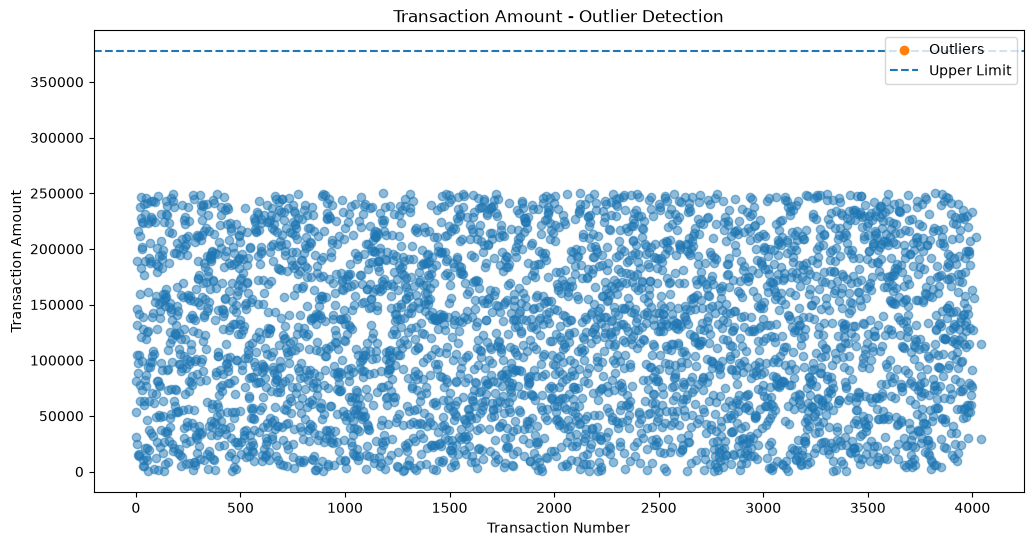

In [63]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df.index,
    df["TransactionAmount"],
    alpha=0.5
)

plt.scatter(
    outliers.index,
    outliers["TransactionAmount"],
    marker="o",
    label="Outliers"
)

plt.axhline(upper_limit, linestyle="--", label="Upper Limit")

plt.title("Transaction Amount - Outlier Detection")
plt.xlabel("Transaction Number")
plt.ylabel("Transaction Amount")
plt.legend()

plt.show()

In [ ]:
#Step11: Validate Data Consistency

In [64]:
df.info()

<class 'pandas.DataFrame'>
Index: 3761 entries, 0 to 4043
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   TransactionID      3761 non-null   str           
 1   CustomerID         3761 non-null   str           
 2   AccountType        3761 non-null   str           
 3   TransactionDate    3761 non-null   datetime64[us]
 4   TransactionAmount  3761 non-null   float64       
 5   TransactionType    3761 non-null   str           
 6   PaymentMethod      3761 non-null   str           
 7   Branch             3761 non-null   str           
 8   Status             3761 non-null   str           
 9   DeviceID           3761 non-null   str           
 10  Merchant           3761 non-null   str           
 11  RiskScore          3761 non-null   int64         
 12  Remarks            3761 non-null   str           
dtypes: datetime64[us](1), float64(1), int64(1), str(10)
memory usage: 625.1 KB


In [65]:
df.isnull().sum()

TransactionID        0
CustomerID           0
AccountType          0
TransactionDate      0
TransactionAmount    0
TransactionType      0
PaymentMethod        0
Branch               0
Status               0
DeviceID             0
Merchant             0
RiskScore            0
Remarks              0
dtype: int64

In [66]:
df.duplicated().sum()

np.int64(0)

In [67]:
df.shape

(3761, 13)

In [ ]:
#Step12: Rename Columns

In [68]:
df = df.rename(columns={
    "TransactionID": "Transaction_ID",
    "CustomerID": "Customer_ID",
    "AccountType": "Account_Type",
    "TransactionDate": "Transaction_Date",
    "TransactionAmount": "Transaction_Amount",
    "TransactionType": "Transaction_Type",
    "PaymentMethod": "Payment_Method",
    "RiskScore": "Risk_Score"
})

In [70]:
df.head(10)

,Transaction_ID,Customer_ID,Account_Type,Transaction_Date,Transaction_Amount,Transaction_Type,Payment_Method,Branch,Status,DeviceID,Merchant,Risk_Score,Remarks
0,TXN000001,C1154,Current,2025-02-19,80992.00,Credit,CARD,Chennai,Pending,D696,Amazon,65,OK
1,TXN000002,C1088,Current,2026-03-05,53713.81,Credit,NEFT,Chennai,Failed,D534,Amazon,73,OK
2,TXN000003,C1228,Business,2025-03-05,30994.30,Debit,UPI,Bengaluru,Completed,D670,Flipkart,38,OK
3,TXN000004,C1553,Savings,2025-11-12,104813.80,Credit,UPI,Hyderabad,Failed,D754,Flipkart,48,OK
4,TXN000005,C1729,Savings,2025-03-03,24402.77,Credit,IMPS,Kochi,Failed,D537,ATM,60,OK
5,TXN000006,C1464,Current,2025-11-03,146411.19,Credit,NEFT,Kochi,Completed,D183,Utility,39,OK
6,TXN000007,C1896,Current,2026-04-05,131322.87,Debit,CARD,Chennai,Completed,D624,Salary,22,OK
7,TXN000008,C1155,Current,2026-03-08,189297.38,Credit,CASH,Chennai,Failed,D686,ATM,44,OK
9,TXN000010,C1718,Current,2026-04-02,15214.32,Debit,CASH,Delhi,Failed,D455,Amazon,60,OK
10,TXN000011,C1625,Savings,2026-05-21,88898.25,Credit,NEFT,Mumbai,Completed,D856,Flipkart,51,OK


In [71]:
df.to_csv(
    "Cleaned_Financial_Transactions.csv",
    index=False
)

In [72]:
import os
os.listdir()

['.ipynb_checkpoints',
 'Cleaned_Financial_Transactions.csv',
 'outliers.ipynb',
 'Uncleaned_Financial_Transactions_Dataset.csv']

In [73]:
df.to_excel("Cleaned_Financial_Transactions.xlsx", index=False)